# 1.3 Estructuración del conjunto de datos

Según el PIIC, esta actividad aplica de forma definitiva las técnicas de ingeniería validadas en la Actividad 1.2 y formatea la información: partición final de las imágenes y sus etiquetas en entrenamiento, validación y prueba (`train/valid/test`), organizadas en la jerarquía que exige YOLO, con Python y sus librerías de sistema (`os`, `shutil`).

**Entregables:**
- **Pipeline de preprocesamiento en código:** `pipeline_dataset_final` en `comun.py`, que va del dataset con etiquetas corregidas al dataset final.
- **Dataset final:** `datos/Data_final`, listo para entrenar los modelos del OE2.

| Entrada | Contenido |
| :--- | :--- |
| `datos/Data_corr_v6` | 669 imágenes con las etiquetas corregidas (Actividad 1.2, limpieza) |
| `resultados/particion.json` | Partición por lote: test fijo y 4 pliegues (Actividad 1.2) |
| `resultados/decision.json` | Configuración elegida en el experimento (Actividad 1.2) |

In [1]:
import json, os, zipfile
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import comun as C

RAIZ = Path.cwd()
DATOS = C.DATOS
LIMPIO = DATOS / 'Data_corr_v6'
FINAL = DATOS / 'Data_final'
SALIDA = RAIZ / 'salida' / '1.3_estructuracion'
C.estilo()
PALETA = C.paleta_clases()
part = json.loads((RAIZ / 'resultados' / 'particion.json').read_text())
decision = json.loads((RAIZ / 'resultados' / 'decision.json').read_text())

## 1. Configuración aplicada

Transformaciones validadas en la Actividad 1.2. La resolución de 1280 px es una desviación declarada de la regla de decisión (informe 1.2, sección 9.4).

In [2]:
pd.DataFrame([
    {'transformación': 'Consolidación a 2 clases', 'aplicación': 'Healthy + Immature → Healthy; Broken, Damage, Fungus, Shriveled, Weeveled → Defect; sin impurezas ni otras semillas'},
    {'transformación': 'Estandarización geométrica', 'aplicación': f"Letterbox a {decision['resolucion']['elegido']} px (lado mayor), relleno gris hasta múltiplo de 32"},
    {'transformación': 'Normalización fotométrica', 'aplicación': 'No' if decision['fotometrico']['elegido'] == 'base' else 'Gray World'},
    {'transformación': 'Balanceo de clases', 'aplicación': 'No' if decision['balanceo']['elegido'] == 'sinbal' else 'Copias por déficit en entrenamiento'},
    {'transformación': 'Normalización de píxeles a [0, 1]', 'aplicación': 'En el dataloader de Ultralytics, al entrenar'},
    {'transformación': 'Aumento de datos', 'aplicación': 'En línea, por defecto de Ultralytics, al entrenar'},
]).set_index('transformación')

,aplicación
transformación,
Consolidación a 2 clases,"Healthy + Immature → Healthy; Broken, Damage, ..."
Estandarización geométrica,"Letterbox a 1280 px (lado mayor), relleno gris..."
Normalización fotométrica,No
Balanceo de clases,No
"Normalización de píxeles a [0, 1]","En el dataloader de Ultralytics, al entrenar"
Aumento de datos,"En línea, por defecto de Ultralytics, al entrenar"


## 2. Partición final

Se conserva la partición por lote de la Actividad 1.2, sin fuga entre conjuntos:
- **Prueba:** el test fijo (70 imágenes, 3 lotes), que no se usó en ninguna decisión.
- **Validación:** uno de los 4 pliegues. Se elige, entre los que tienen entre el 15 y el 25 % de las imágenes, el de composición por subtipo más parecida a la del conjunto de desarrollo. El criterio solo usa etiquetas, no resultados de entrenamiento.
- **Entrenamiento:** los otros 3 pliegues.

In [3]:
PLIEGUE_VAL, criterio = C.elegir_pliegue_validacion(part)
splits = C.particion_final(part, PLIEGUE_VAL)
print(f'Pliegue de validación: {PLIEGUE_VAL}')
criterio

Pliegue de validación: 2


,pliegue,imágenes,% del total,diferencia máxima por subtipo (pp)
0,0,148,28.8,4.25
1,1,101,19.7,8.57
2,2,98,19.1,3.10
3,3,96,18.7,8.00


In [4]:
imgs = part['imagenes']
filas = []
for sp in C.SPLITS_FINALES:
    stems = [s for s, v in splits.items() if v == sp]
    c = Counter()
    for s in stems:
        c.update(imgs[s]['subtipos'])
    t = sum(c.values())
    sano = c['Healthy'] + c['Immature']
    filas.append({'split': sp, 'imágenes': len(stems), '% imágenes': round(100 * len(stems) / len(imgs), 1),
                  'lotes': len({imgs[s]['lote'] for s in stems}), 'cajas': t, 'cajas Healthy': sano, 'cajas Defect': t - sano,
                  '% Healthy': round(100 * sano / t, 1), **{C.CLASES[i]: round(100 * c[C.CLASES[i]] / t, 1) for i in C.SUBTIPOS}})
resumen = pd.DataFrame(filas).set_index('split')
resumen

,imágenes,% imágenes,lotes,cajas,cajas Healthy,cajas Defect,% Healthy,Broken,Damage,Fungus,Healthy,Immature,Shriveled,Weeveled
split,,,,,,,,,,,,,,
train,345,67.3,17,12759,5963,6796,46.7,5.3,4.9,16.9,36.7,10.1,19.7,6.4
valid,98,19.1,5,3486,1656,1830,47.5,4.9,5.2,15.0,40.6,6.9,17.5,9.9
test,70,13.6,3,2467,1131,1336,45.8,4.9,3.7,18.5,40.9,4.9,23.5,3.5


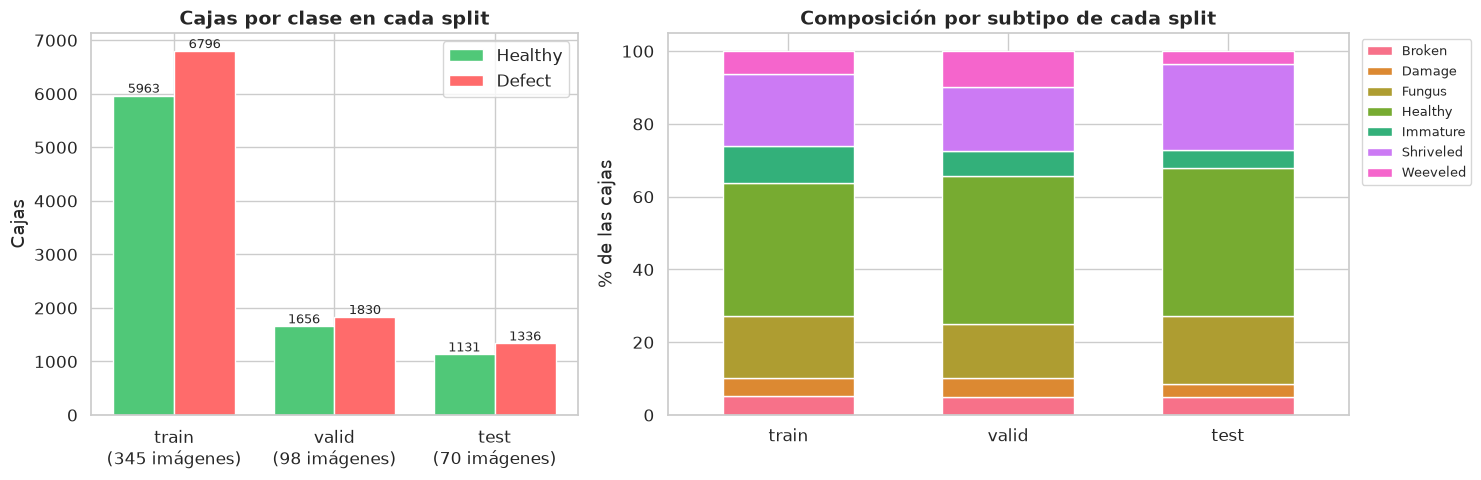

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})
x = np.arange(len(C.SPLITS_FINALES)); w = 0.38
for i, cl in enumerate(C.CLASES_BINARIAS):
    b = a1.bar(x + (i - 0.5) * w, resumen[f'cajas {cl}'], w, color=C.COLOR_BINARIO[cl], label=cl, edgecolor='white')
    a1.bar_label(b, fontsize=9)
a1.set_xticks(x); a1.set_xticklabels([f"{s}\n({resumen.loc[s, 'imágenes']} imágenes)" for s in C.SPLITS_FINALES])
a1.set_ylabel('Cajas'); a1.set_title('Cajas por clase en cada split'); a1.legend()
orden = [C.CLASES[i] for i in C.SUBTIPOS]
resumen[orden].plot(kind='bar', stacked=True, ax=a2, color=[PALETA[c] for c in orden], edgecolor='white', width=0.6)
a2.set_ylabel('% de las cajas'); a2.set_xlabel(''); a2.set_title('Composición por subtipo de cada split')
a2.legend(bbox_to_anchor=(1.01, 1), fontsize=9); a2.tick_params(axis='x', rotation=0)
C.guardar(SALIDA, 'particion_final.png')

## 3. Pipeline de preprocesamiento

`C.pipeline_dataset_final` ejecuta todos los pasos desde `Data_corr_v6`:

1. **Lectura** del dataset con etiquetas corregidas.
2. **Consolidación a 2 clases**, descartando impurezas y otras semillas.
3. **Letterbox** a la resolución elegida y **variante fotométrica** elegida (`generar_datasets`).
4. **Partición** `train/valid/test` y copia a la **jerarquía de YOLO** con `os` y `shutil` (`estructurar_dataset`).
5. **Balanceo** del entrenamiento, solo si se eligió.

Cada split guarda `images/`, `labels/` (clase binaria) y `labels_subtipo/` (subtipo original de cada caja, en la misma línea). YOLO solo lee `images/` y `labels/`; `labels_subtipo/` permite medir el acierto por subtipo en el OE2. El `data.yaml` usa rutas relativas a su propia carpeta, así que el dataset funciona en cualquier equipo.

In [6]:
yaml = C.pipeline_dataset_final(LIMPIO, part, decision, DATOS, FINAL, PLIEGUE_VAL)
print(yaml.read_text())
for sp in C.SPLITS_FINALES:
    for sub in ('images', 'labels', 'labels_subtipo'):
        print(f"Data_final/{sp}/{sub}/".ljust(32), len(os.listdir(FINAL / sp / sub)), 'archivos')

# Dataset final: maíz sano / defectuoso (Actividad 1.3)
train: train/images
val: valid/images
test: test/images
nc: 2
names: ["Healthy", "Defect"]

Data_final/train/images/         345 archivos
Data_final/train/labels/         345 archivos
Data_final/train/labels_subtipo/ 345 archivos
Data_final/valid/images/         98 archivos
Data_final/valid/labels/         98 archivos
Data_final/valid/labels_subtipo/ 98 archivos
Data_final/test/images/          70 archivos
Data_final/test/labels/          70 archivos
Data_final/test/labels_subtipo/  70 archivos


## 4. Verificaciones

Controles automáticos sobre el dataset final. Todos deben dar `OK`.

In [7]:
from ultralytics.data.utils import check_det_dataset

origen = DATOS / f"Data_2c_{decision['resolucion']['elegido']}_{decision['fotometrico']['elegido']}"
res = decision['resolucion']['elegido']
chequeos = []
def chequeo(nombre, ok, detalle=''):
    chequeos.append({'verificación': nombre, 'resultado': 'OK' if ok else 'FALLA', 'detalle': detalle})

por_split = {sp: sorted(p.stem for p in (FINAL / sp / 'images').glob('*.jpg')) for sp in C.SPLITS_FINALES}
chequeo('Imágenes por split según la partición',
        all(len(por_split[sp]) == list(splits.values()).count(sp) for sp in C.SPLITS_FINALES),
        ', '.join(f'{sp}: {len(v)}' for sp, v in por_split.items()))
chequeo('Cada imagen tiene su etiqueta y su etiqueta de subtipo, y viceversa',
        all(sorted(p.stem for p in (FINAL / sp / sub).glob('*.txt')) == por_split[sp]
            for sp in C.SPLITS_FINALES for sub in ('labels', 'labels_subtipo')))
todas = [s for v in por_split.values() for s in v]
chequeo('Ninguna imagen en dos splits', len(todas) == len(set(todas)), f'{len(todas)} imágenes únicas')
lotes = {sp: {imgs[s]['lote'] for s in v} for sp, v in por_split.items()}
chequeo('Ningún lote de captura en dos splits (sin fuga)',
        not (lotes['train'] & lotes['valid'] or lotes['train'] & lotes['test'] or lotes['valid'] & lotes['test']),
        ', '.join(f'{sp}: {len(v)} lotes' for sp, v in lotes.items()))

errores, n_cajas = 0, 0
for sp in C.SPLITS_FINALES:
    for f in (FINAL / sp / 'labels').glob('*.txt'):
        for linea in f.read_text().strip().splitlines():
            v = linea.split(); n_cajas += 1
            if len(v) != 5 or v[0] not in ('0', '1') or not all(0 < float(x) <= 1 for x in v[1:]):
                errores += 1
chequeo('Formato YOLO: 5 valores, clase 0 o 1, coordenadas normalizadas', errores == 0, f'{n_cajas} cajas, {errores} con error')

tamanos = Counter(Image.open(p).size for sp in C.SPLITS_FINALES for p in (FINAL / sp / 'images').glob('*.jpg'))
chequeo(f'Lado mayor de {res} px y ambos lados múltiplos de 32',
        all(max(t) == res and t[0] % 32 == 0 and t[1] % 32 == 0 for t in tamanos),
        ', '.join(f'{a}×{b}: {n}' for (a, b), n in tamanos.most_common()))

iguales = all((FINAL / sp / sub / f'{s}{ext}').read_bytes() == (origen / ('test' if sp == 'test' else 'dev') / sub / f'{s}{ext}').read_bytes()
              for sp, v in por_split.items() for s in v for sub, ext in (('images', '.jpg'), ('labels', '.txt')))
chequeo(f'Archivos idénticos a los del experimento ({origen.name})', iguales)

info = check_det_dataset(str(FINAL / 'data.yaml'))
chequeo('data.yaml válido para Ultralytics', info['nc'] == 2 and all(Path(info[k]).exists() for k in ('train', 'val', 'test')),
        f"nc = {info['nc']}, names = {list(info['names'].values())}")
pd.DataFrame(chequeos).set_index('verificación')

,resultado,detalle
verificación,,
Imágenes por split según la partición,OK,"train: 345, valid: 98, test: 70"
"Cada imagen tiene su etiqueta y su etiqueta de subtipo, y viceversa",OK,
Ninguna imagen en dos splits,OK,513 imágenes únicas
Ningún lote de captura en dos splits (sin fuga),OK,"train: 17 lotes, valid: 5 lotes, test: 3 lotes"
"Formato YOLO: 5 valores, clase 0 o 1, coordenadas normalizadas",OK,"18712 cajas, 0 con error"
Lado mayor de 1280 px y ambos lados múltiplos de 32,OK,"960×1280: 468, 1280×960: 35, 1280×864: 7, 864×..."
Archivos idénticos a los del experimento (Data_2c_1280_base),OK,
data.yaml válido para Ultralytics,OK,"nc = 2, names = ['Healthy', 'Defect']"


## 5. Muestras del dataset final

Una imagen de cada split con sus cajas (verde: `Healthy`; rojo: `Defect`).

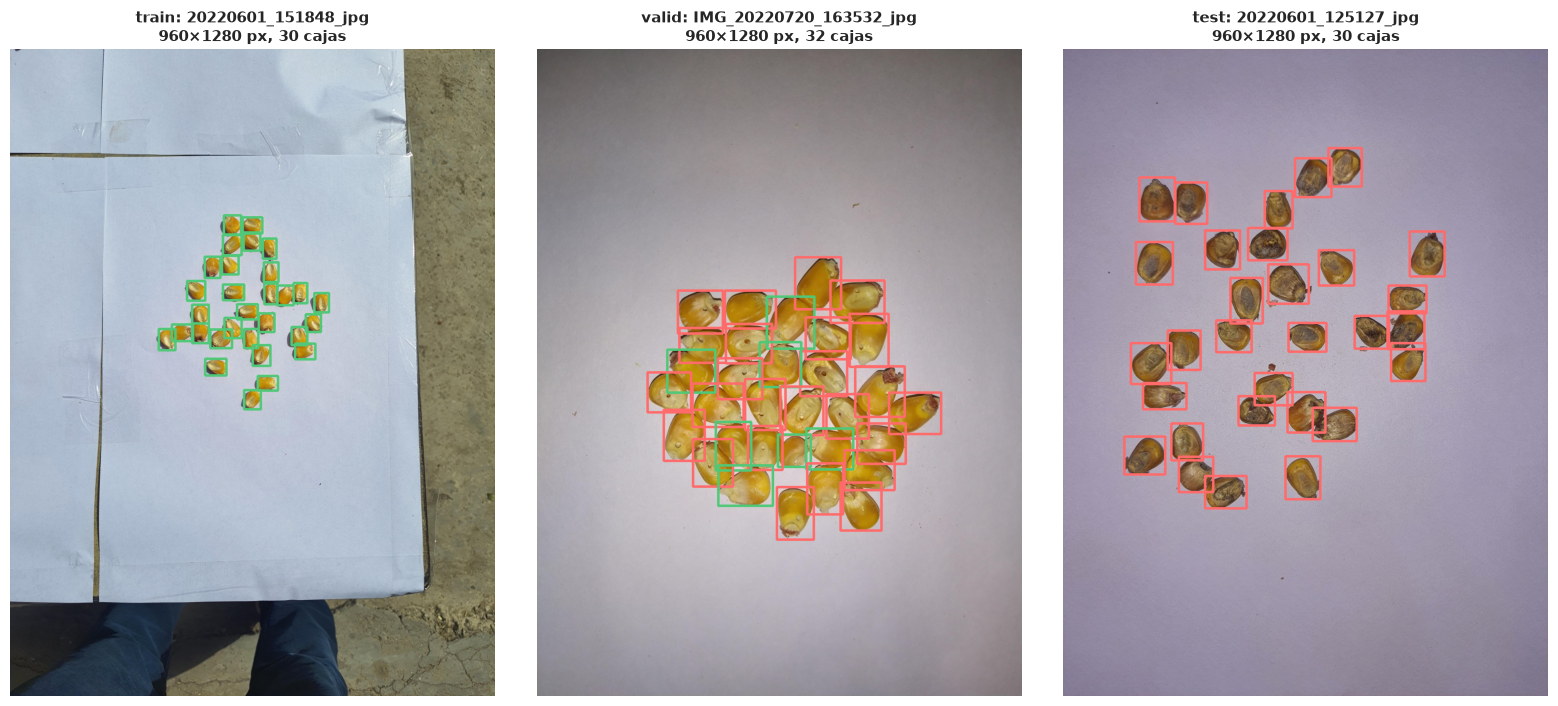

In [8]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 3, figsize=(16, 7))
for ax, sp in zip(axes, C.SPLITS_FINALES):
    s = por_split[sp][rng.integers(len(por_split[sp]))]
    img = cv2.cvtColor(cv2.imread(str(FINAL / sp / 'images' / f'{s}.jpg')), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    cajas, clases = C.leer_yolo(FINAL / sp / 'labels' / f'{s}.txt')
    for (cx, cy, w, h), cl in zip(cajas, clases):
        color = tuple(int(C.COLOR_BINARIO[C.CLASES_BINARIAS[cl]][i:i + 2], 16) for i in (1, 3, 5))
        cv2.rectangle(img, (int((cx - w / 2) * W), int((cy - h / 2) * H)), (int((cx + w / 2) * W), int((cy + h / 2) * H)), color, 3)
    ax.imshow(img); ax.axis('off')
    ax.set_title(f'{sp}: {C.nombre_base(s)}\n{W}×{H} px, {len(cajas)} cajas', fontsize=11)
C.guardar(SALIDA, 'muestras_dataset_final.png')

## 6. Paquete para la nube

Los entrenamientos del OE2 a 1280 px necesitan más VRAM que la GPU local (~12 GB con lote 8), así que se ejecutan en la nube. `nube/oe1_dataset_final.zip` contiene `Data_final` completo; tras descomprimirlo, se entrena con `data='Data_final/data.yaml'` e `imgsz=1280`.

In [9]:
zip_final = C.NUBE / 'oe1_dataset_final.zip'
zip_final.parent.mkdir(exist_ok=True)
archivos = sorted(p for p in FINAL.rglob('*') if p.is_file())
with zipfile.ZipFile(zip_final, 'w') as z:
    for p in archivos:
        z.write(p, p.relative_to(DATOS), compress_type=zipfile.ZIP_STORED if p.suffix == '.jpg' else zipfile.ZIP_DEFLATED)
print(f'{zip_final} ({zip_final.stat().st_size / 1e6:.0f} MB, {len(archivos)} archivos)')

/home/ismael/Documents/Tesis/maiz-yolo11/nube/oe1_dataset_final.zip (154 MB, 1540 archivos)
